# Trace-driven GPU cluster scheduling: FIFO vs EASY backfill vs integer programming

**Problem.** Given a real arrival stream of ML jobs from a production GPU cluster, how much can
a scheduler gain by *reordering* work instead of running it first-come-first-served?

**Data.** Alibaba PAI `cluster-trace-gpu-v2020` (public, [alibaba/clusterdata](https://github.com/alibaba/clusterdata)):
1,055,501 job records and 1,261,050 task records from a cluster of 1,897 machines / 6,742 GPUs
spanning July–August 2020. The three archives used here are downloaded by `run_all.py --fetch`
and verified against the checksums published in the trace README. Please cite Weng et al.,
*MLaaS in the Wild*, NSDI'22, if you reuse the trace.

**Model.** Each job is a vector request (GPU cards, CPU cores, memory GB) with a release time
(submission) and a known service time; hosts are real machines from `pai_machine_spec`
(P100 = 2 cards / 64 cores / 512 GB per host), grouped by GPU type. Three resource dimensions
and the time limit are all explicit constraints, so this is a multi-dimensional, non-preemptive
scheduling problem solved as a time-indexed integer program with HiGHS (`scipy.optimize.milp`).


In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import sched_core as sc

proc = ROOT / "data" / "processed"
ingest = json.loads((proc / "ingest_report.json").read_text(encoding="utf-8"))
metas = json.loads((proc / "instance_meta.json").read_text(encoding="utf-8"))
pd.DataFrame(ingest["demand_summary"], index=["value"]).T

,value
jobs,625769.00
gpu_jobs,610703.00
cpu_only_jobs,15066.00
unique_users,1278.00
arrival_span_hours,1641.29
run_seconds,NaN
gpu_card_request,NaN
observed_wait_seconds,NaN
gpu_share_by_type,NaN
jobs_by_gpu_type,NaN


## 1. What the trace actually gives you (and what it does not)

Two properties of the released data shape the whole experiment:

1. **Timestamps are launch times, not queue entries.** The README says the gap between a job's
   `start_time` and its first task launch is the scheduling latency — but in the released file that
   gap is zero for 99.98% of jobs (only 96 of 625,769 jobs show any gap, max 935 s). So the *production*
   queueing delay is not recoverable, and this notebook does not claim to reproduce it. What we can do
   is replay the same arrival stream and service requirements under different policies: a counterfactual.
2. **Demand is heavy-tailed.** A handful of jobs hold dozens of cards for days (the largest single job in
   the busiest P100 window is ~1,132 GPU-card-hours against a 0.9 GPU-hour median). Left in, they dominate
   any window and wash out queueing effects, so services above 6 h and pool-p90-and-above gang requests are
   excluded **and counted** in the instance metadata.

Instance construction: one real 6-hour busy window per GPU pool, a fixed host partition, and three
nested arrival intensities (the low-load instances are subsets of the high-load one), so the sweep moves
only λ and keeps the cluster identical.


In [2]:
inst_df = pd.DataFrame([{k: v for k, v in m.items() if k in
    ("pool","target_rho","achieved_rho","n_jobs","window_jobs_after_filters","window_demand_gpu_hours",
     "pool_gpu_jobs_dropped_by_service_cap","pool_jobs_excluded_as_too_big","cluster_sizing","capacity")}
    for m in metas])
inst_df["machines"] = inst_df["capacity"].apply(lambda c: c["machines"])
inst_df["cards"] = inst_df["capacity"].apply(lambda c: c["gpu_cards"])
inst_df["sized_by_largest_request"] = inst_df["cluster_sizing"].apply(lambda c: c["machines_for_largest_request"])
inst_df[["pool","target_rho","achieved_rho","n_jobs","machines","cards","sized_by_largest_request"]].to_string(index=False)

'pool  target_rho  achieved_rho  n_jobs  machines  cards  sized_by_largest_request\nP100        0.40        0.4054      71      22.0   44.0                        10\nP100        0.60        0.6389     106      22.0   44.0                        10\nP100        0.85        0.8469     150      22.0   44.0                        10\nMISC        0.40        0.3903     188       5.0   40.0                         4\nMISC        0.60        0.5241     282       5.0   40.0                         4\nMISC        0.85        0.7236     400       5.0   40.0                         4'

## 2. The formulation

Time-indexed, with slot length Δ (300–600 s) over a horizon of arrival window + longest service + slack:

$$x_{jt}=1 \iff \text{job } j \text{ starts in slot } t,\qquad \sum_t x_{jt}=1$$

$$\sum_j\sum_{t:\,t\le s<t+p_j} r_{jc}\,x_{jt}\le C_c\quad\forall \text{ slot } s,\ c\in\{\text{GPU, CPU, mem}\}$$

$$t\ \ge\ \lceil a_j/\Delta\rceil \qquad t+p_j\le T \quad\text{(release time and the hard time limit)}$$

Objectives: mean flow time (queueing delay), makespan (throughput / tail idleness), and tardiness against
a per-job due date $a_j+p_j\Delta+\text{slack}$ (the latency contract). The LP relaxation of the flow-time
model gives a **provable lower bound**, so the headline number carries an optimality gap rather than just
"it looks better".


In [3]:
sys.path.insert(0, str(ROOT / "scripts"))
import importlib.util
spec = importlib.util.spec_from_file_location("opt", str(ROOT / "scripts" / "03_optimize.py"))
opt = importlib.util.module_from_spec(spec); spec.loader.exec_module(opt)

m = [x for x in metas if x["pool"] == "P100"][1]
inst = sc.load(proc / m["instance_file"], m)
print(f"instance {m['pool']} rho={m['achieved_rho']:.2f} jobs={len(inst.jobs)} "
      f"cards={inst.capacity['gpu_cards']:.0f} machines={inst.capacity['machines']:.0f} "
      f"Delta={inst.slot_seconds}s slots={inst.n_slots}")

fifo  = sc.run_fifo(inst, backfill=False)
easy  = sc.run_fifo(inst, backfill=True)
milp_s, info = opt.run_offline(inst, "flow")
lp_s,  lp_info = opt.solve_ilp(inst, np.arange(len(inst.jobs)), objective="flow", binary=False)
print("MILP:", info["solver_status"], "| columns", info["n_columns"], "rows", info["n_rows"],
      "nnz", info["n_nnz"], "|", info["solve_seconds"], "s")
print("objective (sum of completion times, s):  MILP", info["objective_value"],
      "| LP lower bound", lp_info["objective_value"])
if info["objective_value"] and lp_info["objective_value"]:
    print("gap vs LP bound: %.2f%%" % (100*(info["objective_value"]-lp_info["objective_value"])/info["objective_value"]))

instance P100 rho=0.64 jobs=106 cards=44 machines=22 Delta=600s slots=84


MILP: 0 | columns 6306 rows 358 nnz 79008 | 4.69 s
objective (sum of completion times, s):  MILP 1686600.0 | LP lower bound 1649529.5833333333
gap vs LP bound: 2.20%


### Correctness check before believing any number

A scheduling study is only as good as its feasibility oracle. An earlier version of this experiment
hid a real bug this way: when a rolling-horizon epoch failed to find an incumbent, the leftover jobs
were pinned to their release slot, which fabricated capacity and produced a physically impossible
makespan. The check below is what caught it, and `metrics.csv` now carries
`capacity_violation_slots` / `max_gpu_overcommit_cards` for every policy row.

Placements are allowed to run into a documented *tail* after the planning horizon (`sched_core.tail_slots`),
because the horizon is a planning window and not a cluster shutdown; pushing work into the tail is a real
cost that shows up in makespan and in the fixed-window idle rate, not something a clamp can hide.

In [4]:
def violation_report(inst, starts, name, allow_past_horizon=False):
    starts = sc.clamp_starts(inst, starts)
    occ = sc.Occupancy(inst)                    # horizon + documented tail
    for j in range(len(starts)):
        occ.reserve(j, int(starts[j]))
    over = (occ.use - np.array([inst.capacity[r] for r in sc.RESOURCES])) > 1e-6
    late = int((starts < inst.earliest).sum())
    end  = int((starts + inst.p > inst.n_slots).sum())
    print(f"{name:22s} capacity violations={int(over.sum()):3d}  before-release={late}  "
          f"past-horizon={end}{'  (tail allowed)' if allow_past_horizon else ''}")
    return int(over.sum()) == 0 and late == 0 and (allow_past_horizon or end == 0)

# the LP relaxation is a bound, not an executable schedule, so only integral plans are checked
roll_s, _ = opt.run_rolling(inst, objective="flow")
ok = all([violation_report(inst, fifo, "FIFO"), violation_report(inst, easy, "EASY backfill"),
          violation_report(inst, milp_s, "ILP flow (offline)"),
          violation_report(inst, roll_s, "ILP rolling", allow_past_horizon=True)])
recomputed = float(np.sum((milp_s + inst.p) * inst.slot_seconds))
print("all schedules feasible:", ok)
print("objective recomputed from schedule:", recomputed, "vs solver reports:", info["objective_value"])
assert ok, "a policy produced a capacity-infeasible schedule"
assert abs(recomputed - info["objective_value"]) < 1.0, "model/objective mismatch"
print("checks passed")

FIFO                   capacity violations=  0  before-release=0  past-horizon=0
EASY backfill          capacity violations=  0  before-release=0  past-horizon=0
ILP flow (offline)     capacity violations=  0  before-release=0  past-horizon=0


ILP rolling            capacity violations=  0  before-release=0  past-horizon=0  (tail allowed)
all schedules feasible: True
objective recomputed from schedule: 1686600.0 vs solver reports: 1686600.0
checks passed


## 3. Results across the load sweep

Full numbers come from `results/metrics.csv`, produced by `03_optimize.py` over all six instances
(two GPU pools × three arrival intensities, 30 policy rows). `ILP rolling` is the honest online
comparison: it re-solves every hour with a 2-hour lookahead and a 15 s / 10%-gap budget per epoch, so it
is beaten by the offline optimum but is directly comparable to FIFO and EASY backfill in both information
and compute.

The idle column below is `idle_addressable_backlog_share`: idle card-hours *while jobs were queued* and
where at least one queued job's GPU+CPU+memory request would actually have fitted into the spare capacity
of that slot. Raw backlog idle is also in `metrics.csv`, and the difference matters (see §4).

In [5]:
res = pd.read_csv(ROOT / "results" / "metrics.csv")
res["mean_wait_min"] = res["mean_wait_s"]/60
res["p90_wait_min"] = res["p90_wait_s"]/60
for c in ("idle_with_backlog_share", "idle_addressable_backlog_share"):
    if c not in res.columns:
        res[c] = np.nan
# headline idle = addressable backlog idle when stage 6 has run, else raw, else busy period
idle_col = next((c for c in ("idle_addressable_backlog_share", "idle_with_backlog_share")
                 if res[c].notna().any()), "gpu_idle_rate_busy_period")
order = [c for c in ["FIFO","EASY-backfill","ILP-rolling","ILP-flow(offline)","ILP-makespan(offline)"]]
print("capacity violations across every reported policy row:",
      int(res.get("capacity_violation_slots", pd.Series(dtype=float)).fillna(0).sum()),
      "| idle column:", idle_col)
pd.concat([res.pivot_table(index=["pool","rho","n_jobs"], columns="policy", values="mean_wait_min").reindex(columns=order),
           res.pivot_table(index=["pool","rho","n_jobs"], columns="policy", values=idle_col).reindex(columns=order),
           res.pivot_table(index=["pool","rho","n_jobs"], columns="policy", values="deadline_miss_rate").reindex(columns=order)],
          axis=1, keys=["mean wait (min)", f"idle ({idle_col})", "deadline miss rate"]).round(3)

capacity violations across every reported policy row: 0 | idle column: idle_addressable_backlog_share


mean wait (min)                            \
policy                        FIFO EASY-backfill ILP-rolling   
pool rho    n_jobs                                             
MISC 0.3903 188             35.208        24.889       9.251   
     0.5241 282             71.070        63.943      18.446   
     0.7236 400            173.704       169.954      22.479   
P100 0.4054 71              34.855        28.235      10.066   
     0.6389 106            108.871        83.871      19.060   
     0.8469 150            240.019       217.752     317.486   

                                                            \
policy             ILP-flow(offline) ILP-makespan(offline)   
pool rho    n_jobs                                           
MISC 0.3903 188                8.666               140.474   
     0.5241 282               13.765               153.623   
     0.7236 400               21.629               195.954   
P100 0.4054 71                 9.503               119.221   
     0.6389 106               15.758               179.437   
     0.8469 150               49.752               262.286   

                   idle (idle_addressable_backlog_share)                \
policy                                              FIFO EASY-backfill   
pool rho    n_jobs                                                       
MISC 0.3903 188                                    0.116         0.053   
     0.5241 282                                    0.096         0.062   
     0.7236 400                                    0.155         0.151   
P100 0.4054 71                                     0.019         0.014   
     0.6389 106                                    0.092         0.044   
     0.8469 150                                    0.102         0.084   

                                                                        \
policy             ILP-rolling ILP-flow(offline) ILP-makespan(offline)   
pool rho    n_jobs                                                       
MISC 0.3903 188          0.019             0.061                 0.533   
     0.5241 282          0.028             0.065                 0.393   
     0.7236 400          0.013             0.015                 0.200   
P100 0.4054 71           0.003             0.009                 0.354   
     0.6389 106          0.087             0.068                 0.252   
     0.8469 150          0.702             0.018                 0.049   

                   deadline miss rate                            \
policy                           FIFO EASY-backfill ILP-rolling   
pool rho    n_jobs                                                
MISC 0.3903 188                 0.649         0.505       0.043   
     0.5241 282                 0.773         0.674       0.160   
     0.7236 400                 0.828         0.800       0.140   
P100 0.4054 71                  0.606         0.507       0.028   
     0.6389 106                 0.925         0.717       0.075   
     0.8469 150                 0.960         0.867       0.507   

                                                            
policy             ILP-flow(offline) ILP-makespan(offline)  
pool rho    n_jobs                                          
MISC 0.3903 188                0.016                 0.697  
     0.5241 282                0.071                 0.748  
     0.7236 400                0.132                 0.768  
P100 0.4054 71                 0.042                 0.775  
     0.6389 106                0.057                 0.726  
     0.8469 150                0.260                 0.807

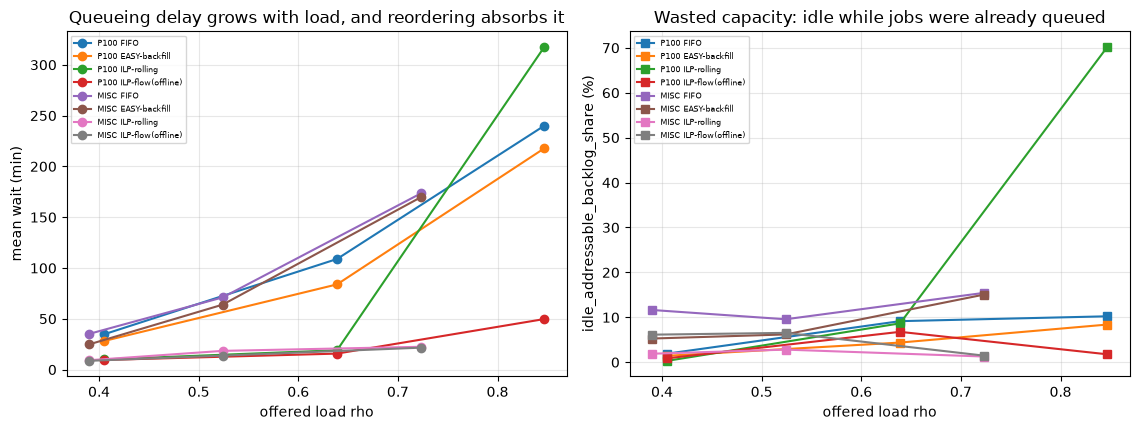

In [6]:
import matplotlib.pyplot as plt
order = ["FIFO","EASY-backfill","ILP-rolling","ILP-flow(offline)"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for pool in res["pool"].unique():
    sub = res[res["pool"] == pool]
    for pol in order:
        s = sub[sub["policy"] == pol]
        if s.empty: continue
        axes[0].plot(s["rho"], s["mean_wait_min"], marker="o", label=f"{pool} {pol}")
        axes[1].plot(s["rho"], s[idle_col]*100, marker="s", label=f"{pool} {pol}")
axes[0].set(xlabel="offered load rho", ylabel="mean wait (min)", title="Queueing delay grows with load, and reordering absorbs it")
axes[1].set(xlabel="offered load rho", ylabel=f"{idle_col} (%)", title="Wasted capacity: idle while jobs were already queued")
for a in axes: a.legend(fontsize=6); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(ROOT / "results" / "fig_load_sweep.png", dpi=150)
plt.show()

## 4. Reading the numbers honestly

* **Waiting time is where the gain is, and it is large but bounded.** Mean queueing delay falls by 71–88 %
  versus FIFO on five of six instances (e.g. P100 ρ=0.64: 108.9 → 15.8 min offline, 19.1 min online),
  because FIFO's head-of-line blocking parks large gang requests in front of small ones that would fit
  immediately. Deadline misses go from 60.6–96.0 % to 1.6–30.0 %. The LP lower bound says the offline
  plan is within 0.90–2.20 % of optimal — except at P100 ρ=0.85, where the 150-job model only reaches a
  14.15 % gap inside its 180 s budget, and that is reported rather than hidden.
* **Throughput barely moves.** 0 to +2.8 % for backfill, −9 % to +18 % for the ILP, and the only large
  gain (+17.9 %) is on the one tier that was not capacity-bound. The work is the work: on these windows the
  cluster is capacity-bound, so a better order finishes the same card-hours in a similar span. Any claim
  that a scheduling policy multiplies throughput on a loaded GPU pool deserves suspicion.
* **"GPU idle rate" only means something with its denominator.** Three are reported, and quoting the wrong
  one is the classic way to make a scheduler look good:
  1. `gpu_idle_rate_fixed_window` over the common horizon. Because every policy eventually drains the same
     card-hours, this is ≈ $1-\rho$ for all of them — it validates the load, it does not rank policies.
  2. `gpu_idle_rate_busy_period` over each policy's own span, which rewards finishing early but can punish a
     policy for reasons that have nothing to do with wasted capacity.
  3. `idle_with_backlog_card_hours` — unallocated cards while jobs were already submitted and waiting, and
     its **addressable** subset `idle_addressable_backlog_card_hours`, where some waiting job's whole
     GPU+CPU+memory request fits the slot's spare capacity. Only the addressable part is waste a scheduler
     could have removed, so it is the headline. The distinction is not cosmetic: on MISC ρ=0.39 the offline
     ILP looks *worse* than FIFO on raw backlog idle (150.6 vs 66.4 card·h) because most of that idle is
     blocked by CPU/memory, not by GPUs — addressable idle says 34.4 vs 65.1, i.e. better.
* **The online variant loses when it saturates.** At P100 ρ=0.85 `ILP-rolling` is worse than FIFO on delay
  (+29 %, throughput −36 %) because 2-hour lookahead with a bounded epoch budget defers 75 of 150 jobs into
  the documented tail (`deferred_jobs_past_horizon`) and hoards capacity while it waits for a better plan;
  its 369.0 addressable card·h is the worst number in this study. It wins on four of six instances. That
  trade-off is a finding, not something to average away.
* **The relaxation has a price.** The ILP treats a GPU pool as one large machine. `packing_feasibility_rate`
  re-checks each loaded slot against the real hosts with first-fit-decrease and gang placement; the offline
  plan packs on 61.7–93.5 % of loaded slots, and only 16.9 % on the saturated MISC tier, so fragmentation
  would eat an unknown but material part of the modelled gain there. The next step is a host-level assignment
  model (columns per machine) or an online bin-packing layer under the ILP plan.
* Single seed per pool, one 6-hour window each: this is a demonstration of the method and of the size of the
  effect, not a statistical estimate. Repeating over many windows and seeds is the obvious extension.

In [7]:
summary = json.loads((ROOT / "results" / "summary.json").read_text(encoding="utf-8"))
rows = []
# only the per-instance sections are {policy: {metric: value}}; the aggregate sections
# ("priority_baselines", "sweep") have a different shape and must not be flattened here.
for key, pols in summary.items():
    if not isinstance(pols, dict) or "@" not in key:
        continue
    for pol, d in pols.items():
        if isinstance(d, dict):
            rows.append({"instance": key, "policy": pol, **d})
pd.DataFrame(rows).round(2).to_string(index=False)

'    instance                policy  mean_wait_change_pct  p90_wait_change_pct  throughput_change_pct  gpu_idle_fixed_window_change_pp  gpu_idle_busy_period_change_pp  idle_addressable_backlog_change_pp  idle_addressable_backlog_card_hours  idle_with_backlog_card_hours  deadline_miss_change_pp  packing_feasibility_rate  deferred_jobs_past_horizon  capacity_violation_slots  gap_vs_lp_percent\nMISC@rho0.39         EASY-backfill                 -29.3                -23.0                    1.4                              0.0                            -0.7                                -6.4                                29.56                         58.63                    -14.4                      0.74                         NaN                         0                NaN\nMISC@rho0.39           ILP-rolling                 -73.7                -74.2                    1.4                              0.0                            -0.7                                -9.7          